# 02 — Allen, Qian, Shan & Zhu (2024), "Dissecting the long-term performance of the Chinese stock market"

A-share parts only (lighthouse.md 5.2). Logic lives in `src/replication/allen/`; this notebook only calls it.
Every printed number in scope is compared with ours under the lighthouse 3.3 tolerances
(`targets/allen_targets.csv`, `results/allen_comparison.csv`); misses link to `docs/deviation_log.md` (ALN-1..7).

Not producible with NYU's CSMAR subscription: the AH premium (Table IX Panel B row; Table X columns (2) and (5)).
Out of scope (cross-country data): Tables II–VII, XII and the other panels.

In [1]:
import pandas as pd
from IPython.display import Image, display
from replication.allen import tables as T
from replication.allen.__main__ import TABLE_FUNCS
from replication.common.compare import compare
pd.set_option("display.width", 200, "display.max_rows", 300, "display.precision", 3)
segs = T.allen_segments(); orig = segs["original"]
print({k: str(v) for k, v in segs.items()})

{'original': 'original 2000-01..2018-12', 'extended': 'extended 2019-01..2025-12', 'full': 'full 2000-01..2025-12'}


In [2]:
ours = pd.concat([f(orig) for f in TABLE_FUNCS.values()], ignore_index=True)
cmp = compare("allen", ours)
scored = cmp[cmp["pass"].notna()]
summary = scored.groupby("table")["pass"].agg(passed=lambda s: int((s == True).sum()), scored="size")
summary.loc["TOTAL"] = summary.sum()
summary

,passed,scored
table,,
F1-2,0,1
F4,0,2
F5,2,2
S3A2,0,2
TI,26,60
TIX,1,5
TVIII,37,48
TX,20,36
TXI,12,16


In [3]:
def show(table):
    x = cmp[cmp["table"] == table][["row", "col", "paper", "ours", "kind", "pass", "source"]].copy()
    x["pass"] = x["pass"].map({True: "ok", False: "MISS"}).fillna("-")
    return x.reset_index(drop=True)
show("TI")

,row,col,paper,ours,kind,pass,source
0,2000,listed_firms,1062.00,1061.000,count,ok,Table I Panel A col (1)
1,2000,soe_firms,744.00,0.000,count,MISS,Table I Panel A col (2)
2,2000,avg_assets_usd_bn,0.24,0.242,count,ok,Table I Panel A col (3) ($ bn; relative 3% rule)
3,2001,listed_firms,1143.00,1140.000,count,ok,Table I Panel A col (1)
4,2001,soe_firms,751.00,2.000,count,MISS,Table I Panel A col (2)
5,2001,avg_assets_usd_bn,0.32,0.321,count,ok,Table I Panel A col (3) ($ bn; relative 3% rule)
6,2002,listed_firms,1205.00,1208.000,count,ok,Table I Panel A col (1)
7,2002,soe_firms,816.00,1.000,count,MISS,Table I Panel A col (2)
8,2002,avg_assets_usd_bn,0.42,0.415,count,ok,Table I Panel A col (3) ($ bn; relative 3% rule)
9,2003,listed_firms,1267.00,1267.000,count,ok,Table I Panel A col (1)


In [4]:
show('TVIII')

,row,col,paper,ours,kind,pass,source
0,A:CEO Duality,mean,0.208,2.109e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
1,A:CEO Duality,median,0.000,0.000e+00,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
2,A:CEO Duality,std,0.406,4.080e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
3,A:CEO Duality,max,1.000,1.000e+00,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
4,A:CEO Duality,min,0.000,0.000e+00,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
5,A:Ownership Concentration,mean,0.539,5.295e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
6,A:Ownership Concentration,median,0.546,5.331e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
7,A:Ownership Concentration,std,0.152,1.543e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
8,A:Ownership Concentration,max,0.891,8.899e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"
9,A:Ownership Concentration,min,0.201,1.815e-01,share_frac,ok,"Table VIII Panel A, Chinese A-share row"


In [5]:
show('TIX')

,row,col,paper,ours,kind,pass,source
0,B:Stock-Level Turnover,mean,3.148,3.073,count,ok,Table IX Panel B
1,B:Stock-Level Turnover,median,2.487,2.351,count,MISS,Table IX Panel B
2,B:Stock-Level Turnover,std,2.383,2.543,count,MISS,Table IX Panel B
3,B:Stock-Level Turnover,min,0.271,0.243,count,MISS,Table IX Panel B
4,B:Stock-Level Turnover,max,12.178,16.403,count,MISS,Table IX Panel B
5,B:Market-Level AH Premium,mean,1.328,NaN,info,-,Table IX Panel B; NOT PRODUCIBLE: needs H-shar...
6,B:Market-Level AH Premium,median,0.843,NaN,info,-,Table IX Panel B; NOT PRODUCIBLE: needs H-shar...
7,B:Market-Level AH Premium,std,1.330,NaN,info,-,Table IX Panel B; NOT PRODUCIBLE: needs H-shar...
8,B:Market-Level AH Premium,min,0.062,NaN,info,-,Table IX Panel B; NOT PRODUCIBLE: needs H-shar...
9,B:Market-Level AH Premium,max,6.604,NaN,info,-,Table IX Panel B; NOT PRODUCIBLE: needs H-shar...


In [6]:
show('TX')

,row,col,paper,ours,kind,pass,source
0,G-Index-A,(1),1.445,1.326,coef,ok,Table X Panel B
1,t(G-Index-A),(1),2.885,2.346,t,MISS,Table X Panel B
2,R2 (%),(1),52.400,50.652,share_pct,ok,Table X Panel B
3,Observations,(1),36044.000,31705.000,count,MISS,Table X Panel B
4,AH Premium,(2),-14.024,NaN,info,-,Table X Panel B; NOT PRODUCIBLE: column uses t...
5,t(AH Premium),(2),-2.335,NaN,info,-,Table X Panel B; NOT PRODUCIBLE: column uses t...
6,R2 (%),(2),4.270,NaN,info,-,Table X Panel B; NOT PRODUCIBLE (AH premium co...
7,Observations,(2),28251.000,NaN,info,-,Table X Panel B; NOT PRODUCIBLE (AH premium co...
8,Stock-Level Turnover,(3),-2.475,-1.108,coef,ok,Table X Panel B
9,t(Stock-Level Turnover),(3),-3.866,-1.176,t,MISS,Table X Panel B


In [7]:
show('TXI')

,row,col,paper,ours,kind,pass,source
0,G-Index-A,(1),0.387,0.552,coef,ok,Table XI Panel C
1,t(G-Index-A),(1),11.452,5.983,t,ok,Table XI Panel C
2,R2 (%),(1),12.520,15.433,share_pct,ok,Table XI Panel C
3,Observations,(1),31085.000,33989.000,count,MISS,Table XI Panel C
4,G-Index-A,(2),0.448,0.728,coef,ok,Table XI Panel C
5,t(G-Index-A),(2),4.812,4.084,t,ok,Table XI Panel C
6,R2 (%),(2),10.230,8.806,share_pct,ok,Table XI Panel C
7,Observations,(2),29885.000,33636.000,count,MISS,Table XI Panel C
8,G-Index-A,(3),0.066,0.166,coef,ok,Table XI Panel C
9,t(G-Index-A),(3),0.823,1.459,t,ok,Table XI Panel C


In [8]:
show('TXIII')

,row,col,paper,ours,kind,pass,source
0,A:RPT Amt Out,(1) coef,-0.026,1.280e-03,coef,MISS,Table XIII
1,A:RPT Amt Out,(1) t,-2.445,4.873e-01,t,MISS,Table XIII
2,A:RPT Amt Out,(1) R2 (%),4.670,3.085e+00,share_pct,ok,Table XIII
3,A:RPT Amt Out,(1) N,33028.000,3.273e+04,count,ok,Table XIII
4,A:RPT Amt Out,(2) coef,0.001,9.000e-04,coef,ok,Table XIII
5,A:RPT Amt Out,(2) t,0.266,1.446e-01,t,ok,Table XIII
6,A:RPT Amt Out,(2) R2 (%),17.660,9.679e+00,share_pct,MISS,Table XIII
7,A:RPT Amt Out,(2) N,2306.000,1.786e+03,count,MISS,Table XIII
8,A:Stock Returns,(3) coef,1.588,4.387e+00,coef,ok,Table XIII
9,A:Stock Returns,(3) t,0.972,2.529e+00,t,MISS,Table XIII


In [9]:
pd.concat([show('F1-2'), show('F4'), show('F5'), show('S3A2')])

,row,col,paper,ours,kind,pass,source
0,BHR_end,all,1.01,1.764,count,MISS,Figure 1 / section I.B text: RMB 1 -> 1.01 rea...
1,BHR_end,small,NaN,9.256,info,-,"Figure 2 (plot only, no printed value; user vi..."
2,BHR_end,medium,NaN,3.075,info,-,"Figure 2 (plot only, no printed value; user vi..."
3,BHR_end,large,NaN,1.572,info,-,"Figure 2 (plot only, no printed value; user vi..."
0,ST,firms_first_st_in_period,572.00,606.000,count,MISS,Section III.A.2 text: 572 firms received ST st...
1,ST,permanent_st_firms,65.00,80.000,count,MISS,Section III.A.2 text: 65 permanent ST firms
2,year-5,roa_weighted,NaN,0.038,info,-,Figure 4 (plot only; text: ROA positive in [-5...
3,year-4,roa_weighted,NaN,0.028,info,-,Figure 4 (plot only; text: ROA positive in [-5...
4,year-3,roa_weighted,NaN,0.036,info,-,Figure 4 (plot only; text: ROA positive in [-5...
5,year-2,roa_weighted,NaN,-0.025,info,-,Figure 4 (plot only; text: ROA positive in [-5...


## Figures (A-share lines; user visual acceptance, lighthouse 8)

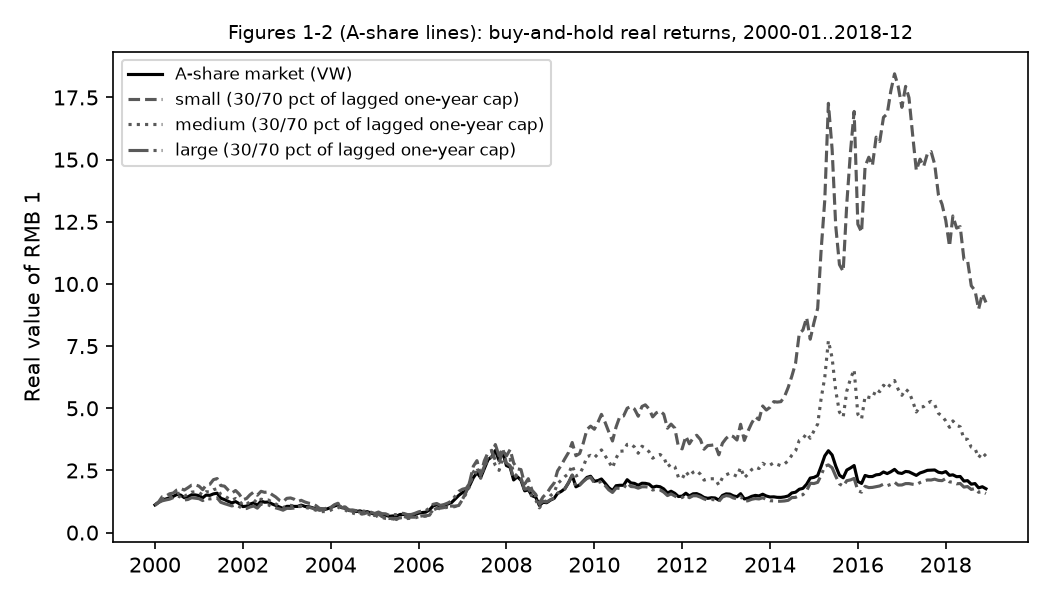

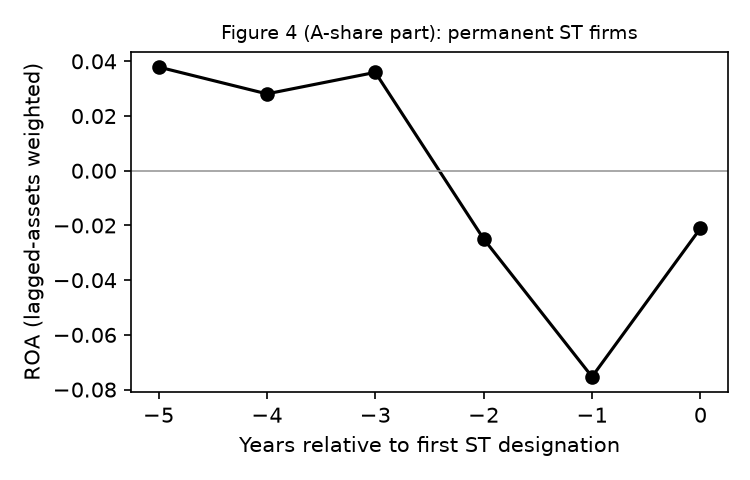

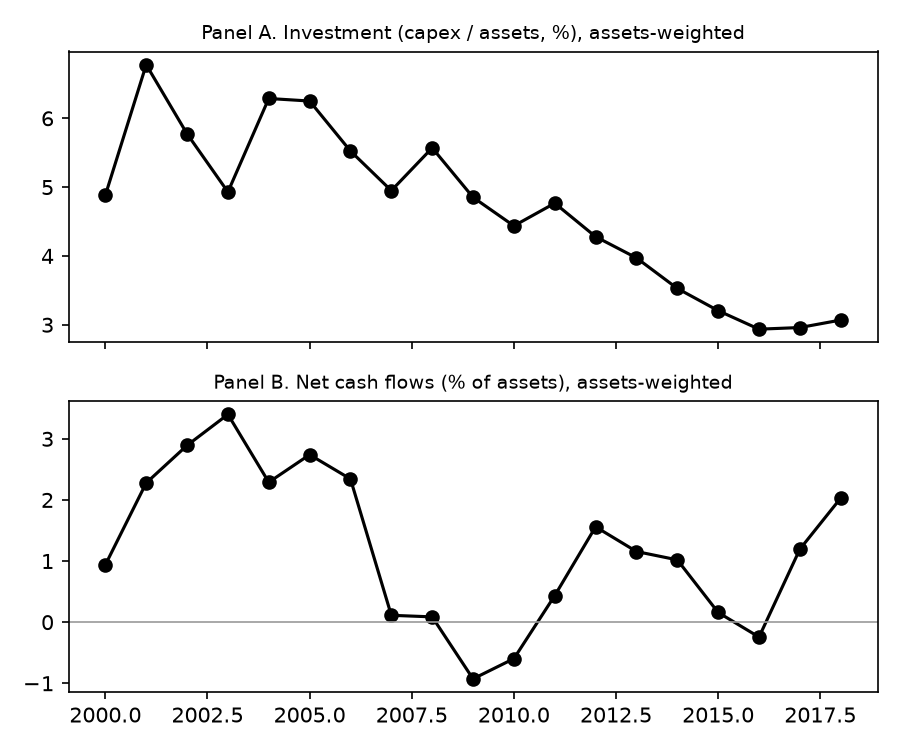

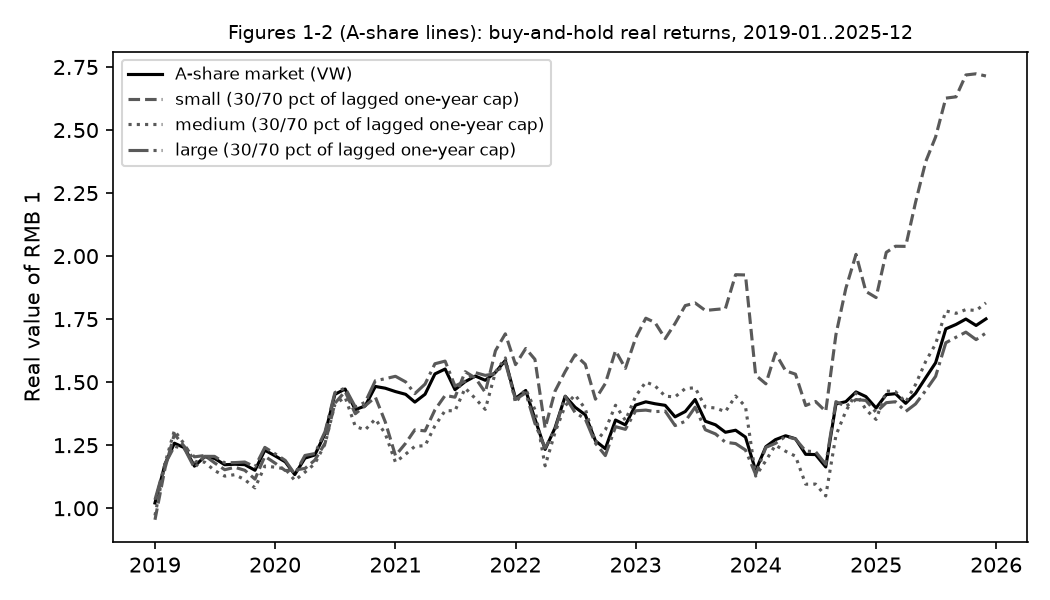

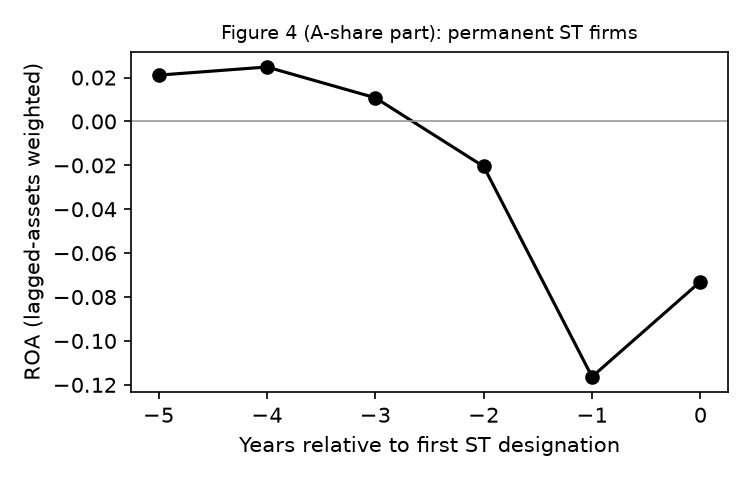

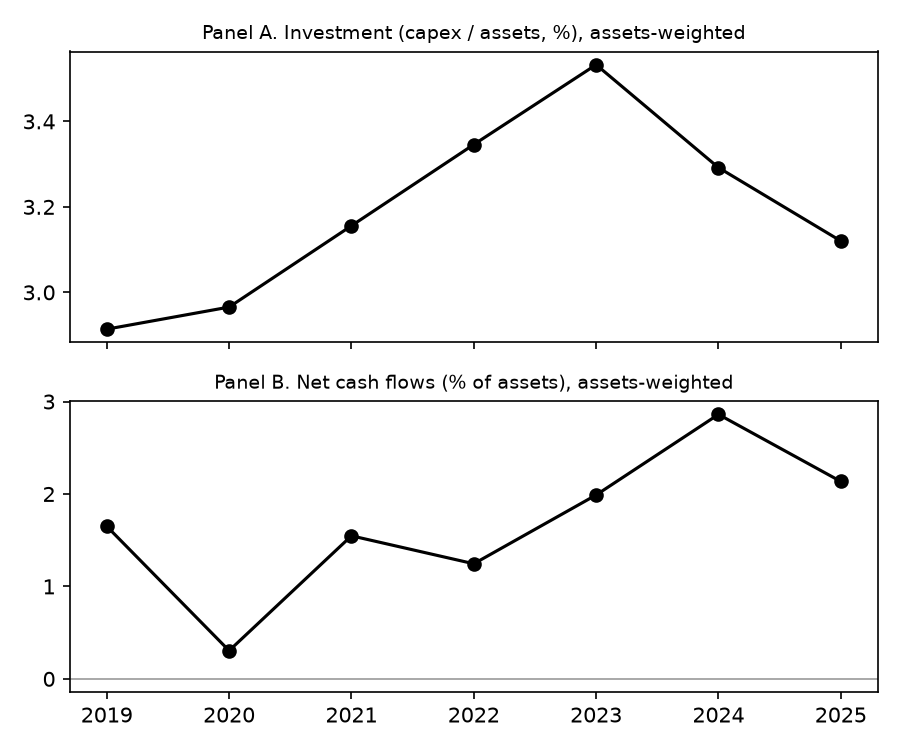

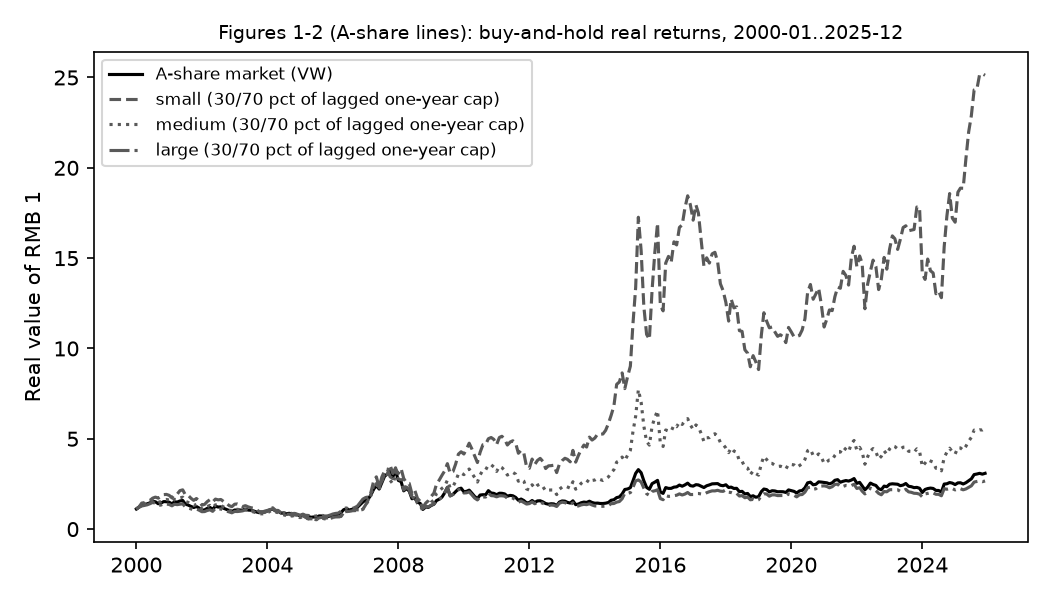

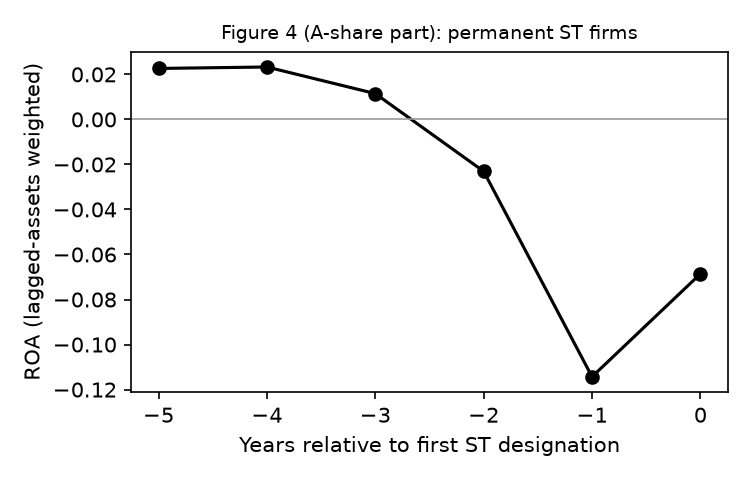

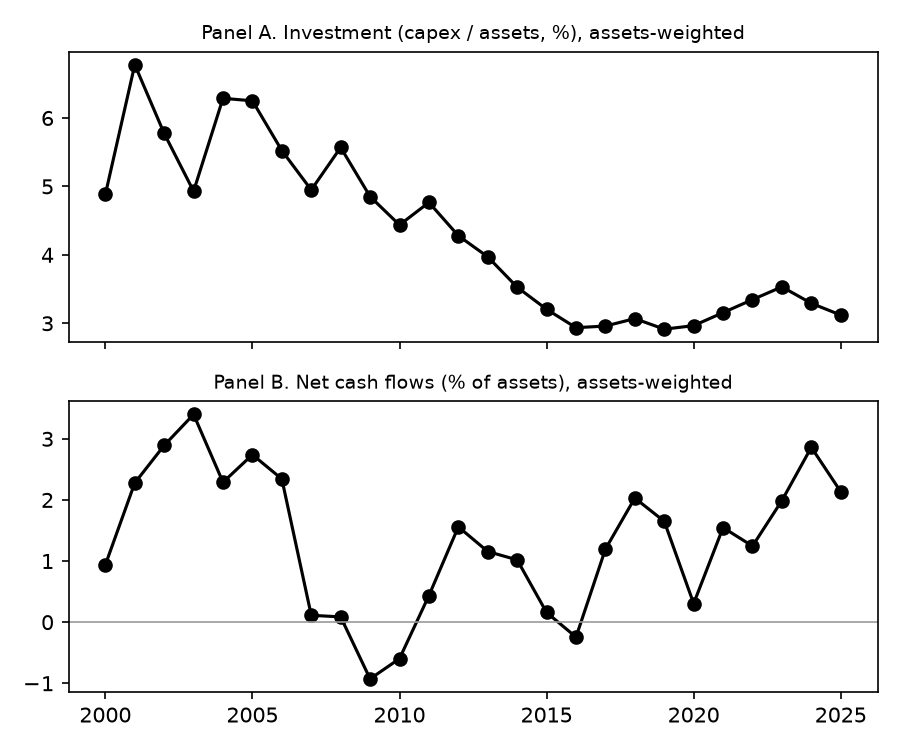

In [10]:
for s in ("original", "extended", "full"):
    for f in (f"fig1_2_bhr_{s}.png", f"fig4_st_roa_{s}.png", f"fig5_investment_ncf_{s}.png"):
        display(Image(filename=str(T.INTERIM.parents[1] / "results" / "allen" / "figures" / f)))

## Extension (lighthouse 6): same functions, later years

In [11]:
rows = []
for name, seg in segs.items():
    b = T.figures12(seg).set_index("col")["value"]
    x = T.table10(seg).pivot(index="row", columns="col", values="value")
    rows.append({"segment": str(seg), "BHR all": b["all"], "BHR small": b["small"], "BHR large": b["large"],
                 "G-Index-A coef (1)": x.loc["G-Index-A", "(1)"], "t": x.loc["t(G-Index-A)", "(1)"]})
pd.DataFrame(rows)

,segment,BHR all,BHR small,BHR large,G-Index-A coef (1),t
0,original 2000-01..2018-12,1.764,9.256,1.572,1.326,2.346
1,extended 2019-01..2025-12,1.751,2.714,1.695,0.670,1.321
2,full 2000-01..2025-12,3.088,25.124,2.665,0.919,1.793
